# AMR Fluorescence Pipeline: multi-method cell + nucleoid segmentation

## Setup: install, mount Drive, unzip data

In [1]:
 !pip install --quiet tifffile "cellpose<4" scikit-image scipy tqdm
from google.colab import drive
drive.mount('/content/drive')
import os

RAW_DIR = "/content/dataset_raw"
os.makedirs(RAW_DIR, exist_ok=True)

zip_path = '/content/drive/MyDrive/Research/All Images.zip'

if os.path.exists(zip_path):
    if not os.listdir(RAW_DIR):          # avoid re-extracting on re-runs
        !unzip -q "{zip_path}" -d "{RAW_DIR}"
    print(f"Data ready in {RAW_DIR}")
else:
    print(f"Error: Zip file not found at {zip_path}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.9/204.9 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 112.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.1/28.1 MB 71.2 MB/s eta 0:00:00
Mounted at /content/drive
Data ready in /content/dataset_raw


## Imports

In [2]:
import json
import math
import random
import shutil
import warnings
import zipfile
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
import torch
from PIL import Image
from tqdm.auto import tqdm

from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from skimage import draw
from skimage.exposure import equalize_adapthist
from skimage.feature import blob_log, graycomatrix, graycoprops, peak_local_max
from skimage.filters import threshold_local, threshold_otsu, unsharp_mask
from skimage.measure import label, regionprops
from skimage.morphology import disk
from skimage.segmentation import find_boundaries, relabel_sequential, watershed

from cellpose import models

warnings.filterwarnings("ignore")

## Configuration (all tunable settings live here)

In [3]:
# ---------------- Paths ----------------
INPUT_DIR        = Path("/content/dataset_raw/")   # contains one sub-folder per treatment class
OUTPUT_DIR       = Path("/content/outputs")                # LOCAL scratch space (fast); cleared per method after syncing to Drive
GROUND_TRUTH_DIR = Path("/content/ground_truth")           # GT/<class>/<image_name>.tif (instance masks)

# ---------------- Permanent storage on Drive ----------------
DRIVE_ROOT   = Path("/content/drive/MyDrive/Research/results")
CELLS_AS_ZIP = True     # True: individual cell PNGs saved to Drive as ONE zip per method (far faster than thousands of files)
FORCE_RERUN  = False    # False: a method already marked complete on Drive is skipped (resume-safe)

# ---------------- Dataset ----------------
CLASSES = ["CIP+ETOH", "RIF+ETOH", "GENT+ETOH", "COAMOX+ETOH", "WT+ETOH"]
PIXEL_SIZE_UM = 0.065           # micrometres per pixel (microscope calibration)
MAX_IMAGES_PER_CLASS = None     # e.g. 3 for a quick test run; None = all images
SEED = 42

# ---------------- Methods ----------------
CELL_METHODS = ["cellpose_omni", "marker_watershed", "adaptive_morphology"]
NUC_METHODS  = ["masked_otsu", "masked_watershed", "blob_log"]
NUC_PREFIX   = {"masked_otsu": "Otsu", "masked_watershed": "Watershed", "blob_log": "BlobLoG"}  # CSV column prefixes

# ---------------- cellpose_omni ----------------
OMNI_MODEL_NAME      = "bact_fluor_cp3"
OMNI_USE_DNA_CHANNEL = False    # False: membrane channel only. True: feed [membrane, DNA] as 2 channels
OMNI_MIN_SIZE        = 15
OMNI_MASK_THRESHOLD  = 0.0
OMNI_FLOW_THRESHOLD  = 0.4
OMNI_DIAMETER        = 30

# ---------------- Filtering / measurement ----------------
MIN_CELL_AREA_PX = 20           # applied to every cell method
NUC_MIN_AREA_PX  = 10           # applied to every nucleoid method
GLCM_LEVELS      = 32           # grey levels for texture features (background excluded)

# ---------------- Exports ----------------
CROP_MARGIN          = 4        # px of context around each individual cell image
SAVE_CELL_IMAGES     = True     # per-cell PNG (enhanced RGB, red = Nile Red, green = DNA)
SAVE_NUCLEOID_CROPS  = False    # per-nucleoid raw crops (many files)
SAVE_OVERLAYS        = True     # per-image QC overlay of cell outlines

# ---------------- Evaluation (needs GT instance masks) ----------------
IOU_THRESHOLDS = [round(x, 2) for x in np.arange(0.50, 1.00, 0.05)]
PRIMARY_IOU_THRESHOLD = 0.80

random.seed(SEED)
np.random.seed(SEED)
DRIVE_ROOT.mkdir(parents=True, exist_ok=True)

## Output folder structure (local scratch; recreated for every method)

In [4]:
def make_dirs():
    for cm in CELL_METHODS:
        for c in CLASSES:
            (OUTPUT_DIR / "masks" / "cells" / cm / c).mkdir(parents=True, exist_ok=True)
            (OUTPUT_DIR / "individual_cells" / cm / c).mkdir(parents=True, exist_ok=True)
            for nm in NUC_METHODS:
                (OUTPUT_DIR / "masks" / "nucleoids" / cm / nm / c).mkdir(parents=True, exist_ok=True)
                (OUTPUT_DIR / "individual_nucleoids" / cm / nm / c).mkdir(parents=True, exist_ok=True)
        (OUTPUT_DIR / "overlays" / cm).mkdir(parents=True, exist_ok=True)

make_dirs()

## Utilities: loading, normalization, mask handling

In [5]:
def load_fluorescence_tiff(path):
    """Return (membrane, dna) as float32 H x W arrays. Accepts C x H x W or H x W x C.
    Channel 0 = Nile Red (membrane), channel 1 = DNA."""
    arr = np.squeeze(tifffile.imread(str(path)))
    if arr.ndim != 3:
        raise ValueError(f"{Path(path).name}: unsupported TIFF shape {arr.shape}")
    if arr.shape[0] <= 8 and arr.shape[1] > 32 and arr.shape[2] > 32:      # channel-first
        arr = np.moveaxis(arr, 0, -1)
    elif not (arr.shape[2] <= 8 and arr.shape[0] > 32 and arr.shape[1] > 32):
        raise ValueError(f"{Path(path).name}: cannot determine channel axis from {arr.shape}")
    return arr[..., 0].astype(np.float32), arr[..., 1].astype(np.float32)


def normalize_channel(ch):
    """Percentile (1-99) normalization to [0, 1]. Used for SEGMENTATION INPUT and display only."""
    p1, p99 = np.percentile(ch, (1, 99))
    denom = p99 - p1 if (p99 - p1) > 0 else 1.0
    return np.clip((ch - p1) / denom, 0.0, 1.0).astype(np.float32)


def clean_labels(labels, min_area):
    """Drop objects smaller than min_area, then relabel 1..N."""
    labels = np.asarray(labels).astype(np.int64)
    if labels.max() == 0:
        return labels.astype(np.uint16)
    areas = np.bincount(labels.ravel())
    small = areas < min_area
    small[0] = False
    labels = np.where(small[labels], 0, labels)
    labels, _, _ = relabel_sequential(labels)
    return labels.astype(np.uint16 if labels.max() < 65535 else np.uint32)


def save_mask(mask, path):
    dtype = np.uint16 if mask.max() < 65535 else np.uint32
    tifffile.imwrite(str(path), mask.astype(dtype))


def circularity(area, perimeter):
    return float(4.0 * np.pi * area / perimeter ** 2) if perimeter > 0 else np.nan


def enhance_channel(img, mask=None):
    """DISPLAY/ML ONLY: percentile stretch (inside mask) + CLAHE + mild sharpening."""
    img = img.astype(np.float32)
    vals = img[mask] if mask is not None and mask.any() else img
    p1, p99 = np.percentile(vals, (1, 99))
    if p99 <= p1:
        p99 = p1 + 1.0
    img = np.clip((img - p1) / (p99 - p1), 0, 1)
    img = equalize_adapthist(img, kernel_size=None, clip_limit=0.02)
    img = unsharp_mask(img, radius=1.0, amount=0.5)
    return np.clip(img, 0, 1).astype(np.float32)

## Device check & cellpose_omni model

In [6]:
use_gpu = torch.cuda.is_available()
print(f"[Device Check] GPU Available: {use_gpu}")
if use_gpu:
    print(f"Device Name: {torch.cuda.get_device_name(0)}")

omni_model = None
if "cellpose_omni" in CELL_METHODS:
    omni_model = models.CellposeModel(gpu=use_gpu, model_type=OMNI_MODEL_NAME)
    print(f"Loaded cellpose_omni model: {OMNI_MODEL_NAME}")

[Device Check] GPU Available: True
Device Name: Tesla T4


100%|██████████| 25.3M/25.3M [00:03<00:00, 8.22MB/s]


Loaded cellpose_omni model: bact_fluor_cp3


## Cell segmentation methods

### a. cellpose_omni

In [7]:
def segment_cells_cellpose_omni(membrane_norm, dna_norm):
    if OMNI_USE_DNA_CHANNEL:
        img, channels = np.stack([membrane_norm, dna_norm], axis=-1), [1, 2]
    else:
        img, channels = membrane_norm, [0, 0]
    masks, _, _ = omni_model.eval(
        img,
        channels=channels,
        min_size=OMNI_MIN_SIZE,
        diameter=OMNI_DIAMETER,
        cellprob_threshold=OMNI_MASK_THRESHOLD,
        flow_threshold=OMNI_FLOW_THRESHOLD,
    )
    return masks

### b. Marker-controlled watershed

In [8]:
def segment_cells_watershed(membrane_norm, dna_norm=None):
    thresh = threshold_otsu(membrane_norm)
    binary = ndi.binary_closing(membrane_norm > thresh, structure=disk(2))
    distance = ndi.distance_transform_edt(binary)
    coords = peak_local_max(distance, min_distance=7, labels=binary.astype(int))
    markers = np.zeros(distance.shape, dtype=np.int32)
    if len(coords) > 0:
        markers[tuple(coords.T)] = np.arange(1, len(coords) + 1)
    return watershed(-distance, markers, mask=binary)

### c. Adaptive (local-threshold) morphology

In [9]:
def segment_cells_adaptive(membrane_norm, dna_norm=None):
    local_thresh = threshold_local(membrane_norm, block_size=35, offset=0.02)
    binary = ndi.binary_opening(membrane_norm > local_thresh, structure=disk(1))
    binary = ndi.binary_closing(binary, structure=disk(2))
    return label(binary)


CELL_SEGMENTERS = {
    "cellpose_omni": segment_cells_cellpose_omni,
    "marker_watershed": segment_cells_watershed,
    "adaptive_morphology": segment_cells_adaptive,
}

## Nucleoid segmentation methods

In [10]:
def _paste_components(window, labeled, nuc_id, min_area):
    """Copy connected components >= min_area into `window` (a view of the full mask) with unique IDs."""
    if labeled.max() == 0:
        return nuc_id
    areas = np.bincount(labeled.ravel())
    for i in np.nonzero(areas >= min_area)[0]:
        if i == 0:
            continue
        window[labeled == i] = nuc_id
        nuc_id += 1
    return nuc_id

### a. Masked Otsu (per cell)

In [11]:
def segment_nucleoids_otsu(cell_mask, dna_raw, ctx):
    nuc_mask = np.zeros(cell_mask.shape, dtype=np.uint32)
    nuc_id = 1
    for prop in regionprops(cell_mask):
        minr, minc, maxr, maxc = prop.bbox
        sub_c = cell_mask[minr:maxr, minc:maxc] == prop.label
        sub_dna = dna_raw[minr:maxr, minc:maxc]
        vals = sub_dna[sub_c]
        if vals.size > 20 and np.ptp(vals) > 0:
            th = threshold_otsu(vals)
            sub_nuc = ndi.binary_opening((sub_dna > th) & sub_c, structure=disk(1))
            nuc_id = _paste_components(nuc_mask[minr:maxr, minc:maxc], label(sub_nuc), nuc_id, NUC_MIN_AREA_PX)
    return nuc_mask

### b. Masked watershed (per cell)

In [12]:
def segment_nucleoids_watershed(cell_mask, dna_raw, ctx):
    nuc_mask = np.zeros(cell_mask.shape, dtype=np.uint32)
    nuc_id = 1
    for prop in regionprops(cell_mask):
        minr, minc, maxr, maxc = prop.bbox
        sub_c = cell_mask[minr:maxr, minc:maxc] == prop.label
        sub_dna = dna_raw[minr:maxr, minc:maxc]
        vals = sub_dna[sub_c]
        if vals.size > 20 and np.ptp(vals) > 0:
            th = threshold_otsu(vals)
            bin_nuc = (sub_dna > th) & sub_c
            dist = ndi.distance_transform_edt(bin_nuc)
            coords = peak_local_max(dist, min_distance=3, labels=bin_nuc.astype(int))
            if len(coords) > 0:
                markers = np.zeros(dist.shape, dtype=np.int32)
                markers[tuple(coords.T)] = np.arange(1, len(coords) + 1)
                ws = watershed(-dist, markers, mask=bin_nuc)
                nuc_id = _paste_components(nuc_mask[minr:maxr, minc:maxc], ws, nuc_id, NUC_MIN_AREA_PX)
    return nuc_mask

### c. Blob-LoG detection

In [13]:
def segment_nucleoids_blob(cell_mask, dna_raw, ctx):
    if ctx.get("blobs") is None:                       # detect once per image
        ctx["blobs"] = blob_log(ctx["dna_norm"], min_sigma=1, max_sigma=5, num_sigma=5, threshold=0.08)

    nuc_mask = np.zeros(cell_mask.shape, dtype=np.uint32)
    nuc_id = 1
    for b in ctx["blobs"]:
        y, x = int(b[0]), int(b[1])
        r = int(np.ceil(b[2] * np.sqrt(2)))
        if not (0 <= y < cell_mask.shape[0] and 0 <= x < cell_mask.shape[1]):
            continue
        cell_id = cell_mask[y, x]
        if cell_id == 0:
            continue
        rr, cc = draw.disk((y, x), radius=max(r, 2), shape=cell_mask.shape)
        valid = cell_mask[rr, cc] == cell_id            # stay inside the parent cell
        rr, cc = rr[valid], cc[valid]
        free = nuc_mask[rr, cc] == 0                    # do not overwrite earlier nucleoids
        if free.any():
            nuc_mask[rr[free], cc[free]] = nuc_id
            nuc_id += 1
    return clean_labels(nuc_mask, NUC_MIN_AREA_PX).astype(np.uint32)


NUC_SEGMENTERS = {
    "masked_otsu": segment_nucleoids_otsu,
    "masked_watershed": segment_nucleoids_watershed,
    "blob_log": segment_nucleoids_blob,
}

## Feature extraction + per-cell export helpers

In [14]:
def glcm_features(sub_memb, sub_cell):
    """GLCM texture inside the cell only. Pixels are quantized to 1..GLCM_LEVELS; 0 = background and is dropped."""
    nan = {"Texture_Contrast": np.nan, "Texture_Correlation": np.nan,
           "Texture_Energy": np.nan, "Texture_Homogeneity": np.nan}
    vals = sub_memb[sub_cell]
    if vals.size < 4 or vals.max() <= vals.min():
        return nan
    lo, hi = vals.min(), vals.max()
    q = np.zeros(sub_memb.shape, dtype=np.uint8)
    q[sub_cell] = 1 + np.floor((vals - lo) / (hi - lo + 1e-6) * (GLCM_LEVELS - 1)).astype(np.uint8)
    glcm = graycomatrix(q, distances=[1], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                        levels=GLCM_LEVELS + 1, symmetric=True, normed=False)[1:, 1:]
    sums = glcm.sum(axis=(0, 1), keepdims=True).astype(np.float64)
    if sums.sum() == 0:
        return nan
    glcm = glcm / np.where(sums == 0, 1, sums)
    return {
        "Texture_Contrast": float(graycoprops(glcm, "contrast").mean()),
        "Texture_Correlation": float(graycoprops(glcm, "correlation").mean()),
        "Texture_Energy": float(graycoprops(glcm, "energy").mean()),
        "Texture_Homogeneity": float(graycoprops(glcm, "homogeneity").mean()),
    }


def summarize_nucleoids(props, cell_area_px, prefix):
    """Cell-level aggregate of one nucleoid method. Cells with no nucleoid: count/area = 0, shape/intensity = NaN."""
    keys = ["Count", "Total_Area_um2", "Mean_Length_um", "Mean_Width_um", "Mean_Circularity",
            "Mean_Eccentricity", "Mean_DNA_Intensity", "Max_DNA_Intensity", "Cell_Area_Ratio"]
    if len(props) == 0:
        out = {f"{prefix}_{k}": np.nan for k in keys}
        out[f"{prefix}_Count"] = 0
        out[f"{prefix}_Total_Area_um2"] = 0.0
        out[f"{prefix}_Cell_Area_Ratio"] = 0.0
        return out
    total_px = float(sum(p.area for p in props))
    return {
        f"{prefix}_Count": len(props),
        f"{prefix}_Total_Area_um2": total_px * PIXEL_SIZE_UM ** 2,
        f"{prefix}_Mean_Length_um": float(np.mean([p.major_axis_length for p in props])) * PIXEL_SIZE_UM,
        f"{prefix}_Mean_Width_um": float(np.mean([p.minor_axis_length for p in props])) * PIXEL_SIZE_UM,
        f"{prefix}_Mean_Circularity": float(np.nanmean([circularity(p.area, p.perimeter) for p in props])),
        f"{prefix}_Mean_Eccentricity": float(np.mean([p.eccentricity for p in props])),
        f"{prefix}_Mean_DNA_Intensity": float(np.mean([p.mean_intensity for p in props])),
        f"{prefix}_Max_DNA_Intensity": float(np.max([p.max_intensity for p in props])),
        f"{prefix}_Cell_Area_Ratio": total_px / cell_area_px if cell_area_px > 0 else np.nan,
    }


def intensity_stats(px, prefix):
    return {
        f"{prefix}_Mean": float(np.mean(px)), f"{prefix}_Median": float(np.median(px)),
        f"{prefix}_Min": float(np.min(px)), f"{prefix}_Max": float(np.max(px)),
        f"{prefix}_Std": float(np.std(px)), f"{prefix}_Variance": float(np.var(px)),
    }


def measure_and_export_cells(cell_method, treatment, fname, cell_mask, membrane, dna, nuc_masks):
    """Measure every cell of one (image, cell_method), save method-wise crops, return records."""
    H, W = cell_mask.shape
    cell_rows, nuc_rows = [], []

    cell_dir = OUTPUT_DIR / "individual_cells" / cell_method / treatment

    for cell in regionprops(cell_mask):
        cid = cell.label
        cell_uid = f"{fname}_cell_{cid}"
        minr, minc, maxr, maxc = cell.bbox
        y0, x0 = max(0, minr - CROP_MARGIN), max(0, minc - CROP_MARGIN)
        y1, x1 = min(H, maxr + CROP_MARGIN), min(W, maxc + CROP_MARGIN)
        win = (slice(y0, y1), slice(x0, x1))

        sub_cell = cell_mask[win] == cid                 # excludes neighbouring cells in the padded window
        sub_memb, sub_dna = membrane[win], dna[win]

        # ---- individual cell image (method-wise folder) ----
        png_rel = ""
        if SAVE_CELL_IMAGES:
            rgb = np.zeros((*sub_cell.shape, 3), dtype=np.float32)
            rgb[..., 0] = enhance_channel(sub_memb, sub_cell) * sub_cell     # red   = Nile Red
            rgb[..., 1] = enhance_channel(sub_dna, sub_cell) * sub_cell      # green = DNA
            png_path = cell_dir / f"{cell_uid}.png"
            Image.fromarray((np.clip(rgb, 0, 1) * 255).astype(np.uint8)).save(png_path)
            png_rel = f"{treatment}/{cell_uid}.png"      # path inside individual_cells (zip or folder) on Drive

        # ---- morphology ----
        area_px = float(cell.area)
        len_px, wid_px = float(cell.major_axis_length), float(cell.minor_axis_length)
        row = {
            "Cell_UID": cell_uid, "Cell_Method": cell_method, "Image_ID": fname,
            "Treatment_Class": treatment, "Cell_Label": int(cid),
            "Touches_Border": bool(minr == 0 or minc == 0 or maxr == H or maxc == W),
            "Area_px": area_px, "Area_um2": area_px * PIXEL_SIZE_UM ** 2,
            "Length_px": len_px, "Length_um": len_px * PIXEL_SIZE_UM,
            "Width_px": wid_px, "Width_um": wid_px * PIXEL_SIZE_UM,
            "Perimeter_um": float(cell.perimeter) * PIXEL_SIZE_UM,
            "Aspect_Ratio": len_px / wid_px if wid_px > 0 else np.nan,
            "Circularity": circularity(area_px, cell.perimeter),
            "Eccentricity": float(cell.eccentricity), "Solidity": float(cell.solidity),
            "Orientation_deg": float(np.degrees(cell.orientation)),
            "Centroid_Y_px": float(cell.centroid[0]), "Centroid_X_px": float(cell.centroid[1]),
        }
        # ---- raw intensities + texture ----
        row.update(intensity_stats(sub_memb[sub_cell], "NileRed_Intensity"))
        row.update(intensity_stats(sub_dna[sub_cell], "DNA_Intensity"))
        row.update(glcm_features(sub_memb, sub_cell))

        # ---- nucleoids: every method ----
        for nm in NUC_METHODS:
            sub_nuc = np.where(sub_cell, nuc_masks[nm][win], 0)
            props = regionprops(sub_nuc, intensity_image=sub_dna)
            row.update(summarize_nucleoids(props, area_px, NUC_PREFIX[nm]))

            nuc_dir = OUTPUT_DIR / "individual_nucleoids" / cell_method / nm / treatment
            for k, p in enumerate(props, start=1):
                nuc_uid = f"{cell_uid}_nuc_{k}"
                if SAVE_NUCLEOID_CROPS:
                    crop = np.where(sub_nuc == p.label, sub_dna, 0).astype(np.float32)
                    tifffile.imwrite(str(nuc_dir / f"{nuc_uid}.tif"), crop)
                nuc_rows.append({
                    "Nucleoid_UID": nuc_uid, "Cell_UID": cell_uid,          # Cell_UID = foreign key to cell table
                    "Cell_Method": cell_method, "Nucleoid_Method": nm,
                    "Image_ID": fname, "Treatment_Class": treatment,
                    "Area_um2": p.area * PIXEL_SIZE_UM ** 2,
                    "Length_um": p.major_axis_length * PIXEL_SIZE_UM,
                    "Width_um": p.minor_axis_length * PIXEL_SIZE_UM,
                    "Circularity": circularity(p.area, p.perimeter),
                    "Eccentricity": float(p.eccentricity),
                    "Mean_DNA_Intensity": float(p.mean_intensity),
                    "Max_DNA_Intensity": float(p.max_intensity),
                    "Centroid_Y_px": y0 + float(p.centroid[0]), "Centroid_X_px": x0 + float(p.centroid[1]),
                })

        row["Cell_Image_PNG"] = png_rel
        cell_rows.append(row)

    return cell_rows, nuc_rows

## Drive persistence helpers

In [15]:
def method_dir(cm):
    return DRIVE_ROOT / cm


def is_complete(cm):
    return (method_dir(cm) / "_COMPLETE.json").exists()


def sync_method_to_drive(cm, n_cells, n_nuc):
    """Copy everything produced for ONE cell method from local disk to Drive, then free the local copy."""
    dest = method_dir(cm)
    dest.mkdir(parents=True, exist_ok=True)

    # masks (cells + all nucleoid methods) and QC overlays
    shutil.copytree(OUTPUT_DIR / "masks" / "cells" / cm,     dest / "masks" / "cells",     dirs_exist_ok=True)
    shutil.copytree(OUTPUT_DIR / "masks" / "nucleoids" / cm, dest / "masks" / "nucleoids", dirs_exist_ok=True)
    shutil.copytree(OUTPUT_DIR / "overlays" / cm,            dest / "overlays",            dirs_exist_ok=True)

    # individual segmented cells (and nucleoid crops if enabled)
    src_cells = OUTPUT_DIR / "individual_cells" / cm
    if CELLS_AS_ZIP:
        shutil.make_archive(str(dest / "individual_cells"), "zip", src_cells)
    else:
        shutil.copytree(src_cells, dest / "individual_cells", dirs_exist_ok=True)
    if SAVE_NUCLEOID_CROPS:
        shutil.make_archive(str(dest / "individual_nucleoids"), "zip", OUTPUT_DIR / "individual_nucleoids" / cm)

    # completion marker is written LAST, so a half-copied method is never treated as done
    (dest / "_COMPLETE.json").write_text(json.dumps({
        "cell_method": cm, "cells": n_cells, "nucleoids_all_methods": n_nuc,
        "finished_at": datetime.now().isoformat(), "cells_as_zip": CELLS_AS_ZIP,
    }, indent=2))

    # free local disk
    for p in [OUTPUT_DIR / "individual_cells" / cm, OUTPUT_DIR / "individual_nucleoids" / cm,
              OUTPUT_DIR / "masks" / "cells" / cm, OUTPUT_DIR / "masks" / "nucleoids" / cm,
              OUTPUT_DIR / "overlays" / cm]:
        shutil.rmtree(p, ignore_errors=True)

## Main pipeline: one cell method at a time, saved to Drive after each

In [16]:
def process_image_one_method(fpath, treatment, cm, cell_rows_acc, nuc_rows_acc):
    fname = fpath.stem
    membrane, dna = load_fluorescence_tiff(fpath)
    membrane_norm, dna_norm = normalize_channel(membrane), normalize_channel(dna)
    ctx = {"dna_norm": dna_norm, "blobs": None}

    cell_mask = clean_labels(CELL_SEGMENTERS[cm](membrane_norm, dna_norm), MIN_CELL_AREA_PX)
    save_mask(cell_mask, OUTPUT_DIR / "masks" / "cells" / cm / treatment / f"{fname}_cellmask.tif")

    if SAVE_OVERLAYS:
        display_rgb = (np.stack([membrane_norm, dna_norm, np.zeros_like(dna_norm)], axis=-1) * 255).astype(np.uint8)
        display_rgb[find_boundaries(cell_mask, mode="outer")] = (255, 255, 0)
        Image.fromarray(display_rgb).save(OUTPUT_DIR / "overlays" / cm / f"{treatment}__{fname}.png")

    nuc_masks = {}
    for nm in NUC_METHODS:
        nuc_masks[nm] = NUC_SEGMENTERS[nm](cell_mask, dna, ctx)
        save_mask(nuc_masks[nm], OUTPUT_DIR / "masks" / "nucleoids" / cm / nm / treatment / f"{fname}_nucmask.tif")

    c_rows, n_rows = measure_and_export_cells(cm, treatment, fname, cell_mask, membrane, dna, nuc_masks)
    cell_rows_acc.extend(c_rows)
    nuc_rows_acc.extend(n_rows)
    return len(c_rows), membrane.shape


run_log = []
for cm in CELL_METHODS:
    if is_complete(cm) and not FORCE_RERUN:
        print(f"[{cm}] already on Drive -> skipped (set FORCE_RERUN=True to redo)")
        continue

    print(f"\n{'=' * 70}\nCELL METHOD: {cm}\n{'=' * 70}")
    make_dirs()                                   # local scratch folders are deleted after every sync
    cell_rows, nuc_rows, qc_rows, failed = [], [], [], []

    for treatment in CLASSES:
        img_files = sorted((INPUT_DIR / treatment).glob("*.tif*"))
        if MAX_IMAGES_PER_CLASS:
            img_files = img_files[:MAX_IMAGES_PER_CLASS]
        for fpath in tqdm(img_files, desc=f"{cm} | {treatment}"):
            try:
                n_kept, shp = process_image_one_method(fpath, treatment, cm, cell_rows, nuc_rows)
                qc_rows.append({"Cell_Method": cm, "Treatment_Class": treatment, "Image_ID": fpath.stem,
                                "Cells_Kept": n_kept, "Image_H": shp[0], "Image_W": shp[1]})
            except Exception as exc:
                failed.append({"Image": str(fpath), "Error": f"{type(exc).__name__}: {exc}"})
                print(f"  ERROR {fpath.name}: {type(exc).__name__}: {exc}")

    # ---- CSVs go straight to Drive (method-wise) ----
    tdir, qdir = method_dir(cm) / "tables", method_dir(cm) / "qc"
    tdir.mkdir(parents=True, exist_ok=True); qdir.mkdir(parents=True, exist_ok=True)
    df_c, df_n = pd.DataFrame(cell_rows), pd.DataFrame(nuc_rows)
    df_c.to_csv(tdir / f"{cm}_cells.csv", index=False)        # 1 row / cell, all nucleoid methods as columns
    df_n.to_csv(tdir / f"{cm}_nucleoids.csv", index=False)    # 1 row / nucleoid, linked by Cell_UID
    if not df_c.empty:
        (df_c.groupby("Treatment_Class")
             .agg(Cells=("Cell_UID", "count"), Mean_Area_um2=("Area_um2", "mean"),
                  Mean_Length_um=("Length_um", "mean"), Mean_Width_um=("Width_um", "mean"),
                  Mean_Aspect_Ratio=("Aspect_Ratio", "mean"), Border_Touching=("Touches_Border", "sum"))
             .reset_index().assign(Cell_Method=cm)
             .to_csv(tdir / f"{cm}_summary.csv", index=False))
    pd.DataFrame(qc_rows).to_csv(qdir / "image_qc.csv", index=False)
    pd.DataFrame(failed).to_csv(qdir / "failed_images.csv", index=False)

    # ---- masks, overlays, individual cells -> Drive, then free local disk ----
    sync_method_to_drive(cm, len(df_c), len(df_n))
    run_log.append({"Cell_Method": cm, "Cells": len(df_c), "Nucleoids": len(df_n), "Failed": len(failed)})
    print(f"[{cm}] saved to {method_dir(cm)}  | cells={len(df_c)}  nucleoids={len(df_n)}  failed={len(failed)}")

# run configuration (written once, after the loop)
(DRIVE_ROOT / "run_configuration.json").write_text(json.dumps({
    "created_at": datetime.now().isoformat(), "input_dir": str(INPUT_DIR), "classes": CLASSES,
    "pixel_size_um": PIXEL_SIZE_UM, "cell_methods": CELL_METHODS, "nucleoid_methods": NUC_METHODS,
    "cellpose_omni": {"model": OMNI_MODEL_NAME, "use_dna_channel": OMNI_USE_DNA_CHANNEL, "diameter": OMNI_DIAMETER,
                      "min_size": OMNI_MIN_SIZE, "mask_threshold": OMNI_MASK_THRESHOLD, "flow_threshold": OMNI_FLOW_THRESHOLD},
    "min_cell_area_px": MIN_CELL_AREA_PX, "nuc_min_area_px": NUC_MIN_AREA_PX, "glcm_levels": GLCM_LEVELS,
    "iou_thresholds": IOU_THRESHOLDS, "seed": SEED, "max_images_per_class": MAX_IMAGES_PER_CLASS,
    "note": "Intensities/texture computed from RAW channels; enhanced PNGs are visualization only.",
}, indent=2, default=str))

display(pd.DataFrame(run_log)) if run_log else print("Nothing new was processed.")


CELL METHOD: cellpose_omni


cellpose_omni | CIP+ETOH:   0%|          | 0/285 [00:00<?, ?it/s]

cellpose_omni | RIF+ETOH:   0%|          | 0/279 [00:00<?, ?it/s]

cellpose_omni | GENT+ETOH:   0%|          | 0/199 [00:00<?, ?it/s]

cellpose_omni | COAMOX+ETOH:   0%|          | 0/350 [00:00<?, ?it/s]

...

adaptive_morphology | GENT+ETOH:   0%|          | 0/199 [00:00<?, ?it/s]

adaptive_morphology | COAMOX+ETOH:   0%|          | 0/350 [00:00<?, ?it/s]

adaptive_morphology | WT+ETOH:   0%|          | 0/455 [00:00<?, ?it/s]

[adaptive_morphology] saved to /content/drive/MyDrive/Research/results/adaptive_morphology  | cells=49772  nucleoids=3657477  failed=0


,Cell_Method,Cells,Nucleoids,Failed
0,cellpose_omni,99097,466148,0
1,marker_watershed,101675,482389,0
2,adaptive_morphology,49772,3657477,0


## Visual QC (reads everything back from Drive)

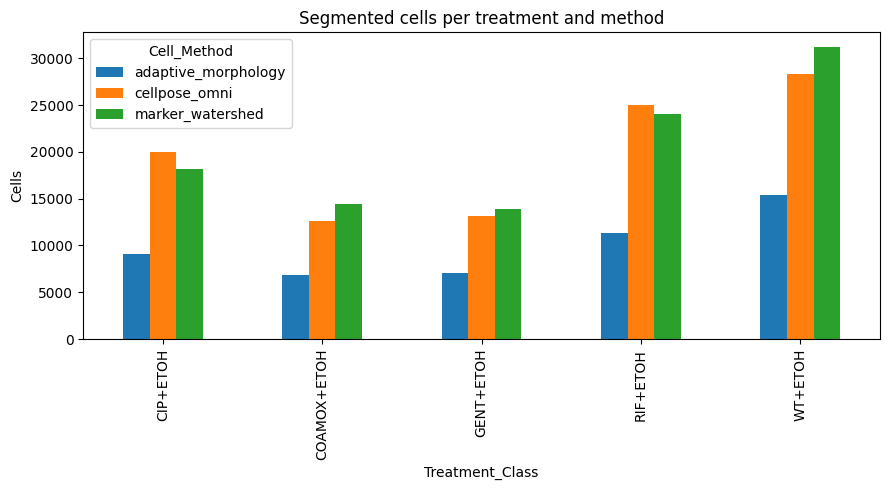

Treatment_Class                       CIP+ETOH  COAMOX+ETOH  GENT+ETOH  \
Cell_Method         Nucleoid_Method                                      
adaptive_morphology blob_log             20086        20534      17266   
                    masked_otsu          55891        64917      39135   
                    masked_watershed    602202       781387     377578   
cellpose_omni       blob_log             14133        13030       9741   
                    masked_otsu          21419        20893      13570   
                    masked_watershed     37055        39694      23978   
marker_watershed    blob_log             20097        19158      16941   
                    masked_otsu          22951        18207      16983   
                    masked_watershed     30520        28141      24442   

Treatment_Class                       RIF+ETOH  WT+ETOH  
Cell_Method         Nucleoid_Method                      
adaptive_morphology blob_log             42103    44664  
                    masked_otsu          58014    94708  
                    masked_watershed    502338   936654  
cellpose_omni       blob_log             30066    33109  
                    masked_otsu          29487    44277  
                    masked_watershed     59987    75709  
marker_watershed    blob_log             41023    44000  
                    masked_otsu          34718    42403  
                    masked_watershed     61399    61406

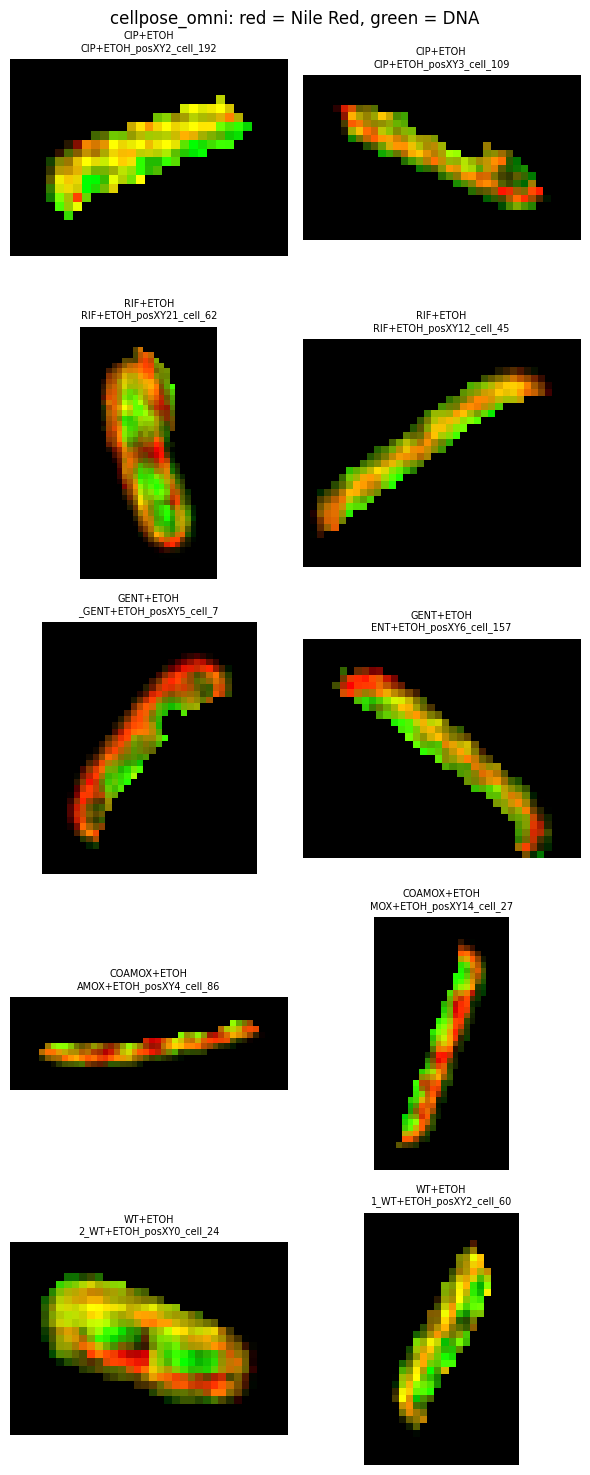

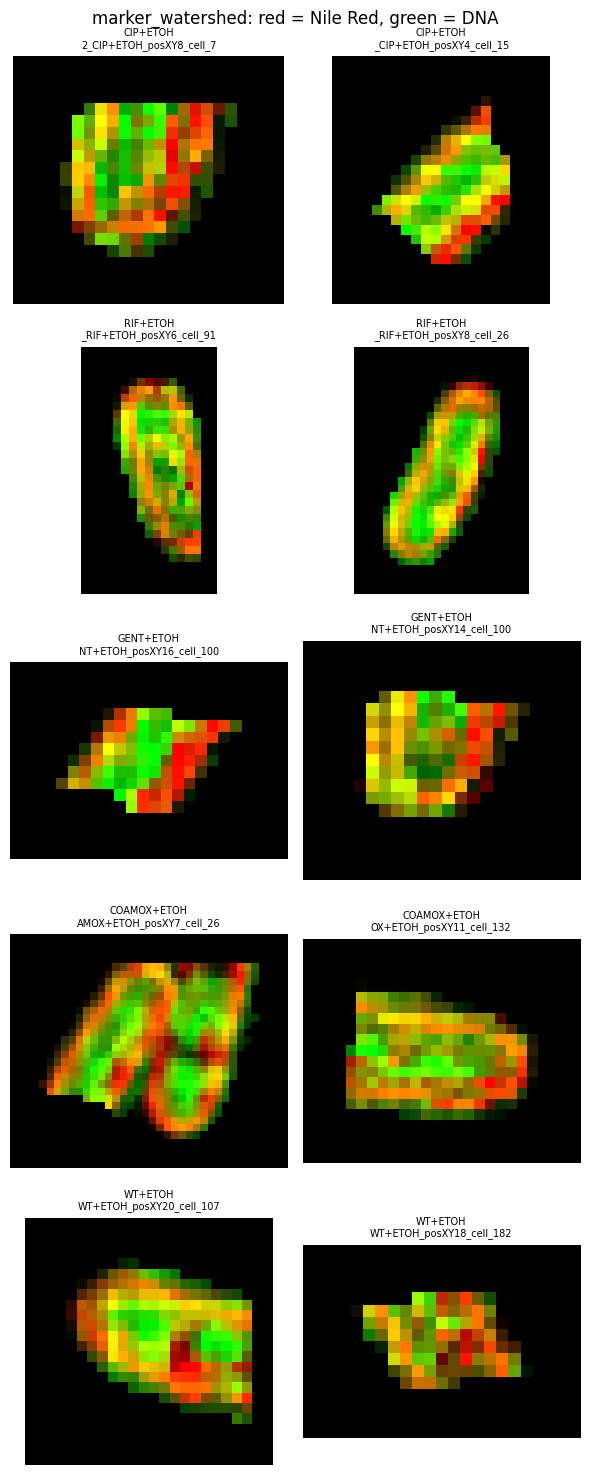

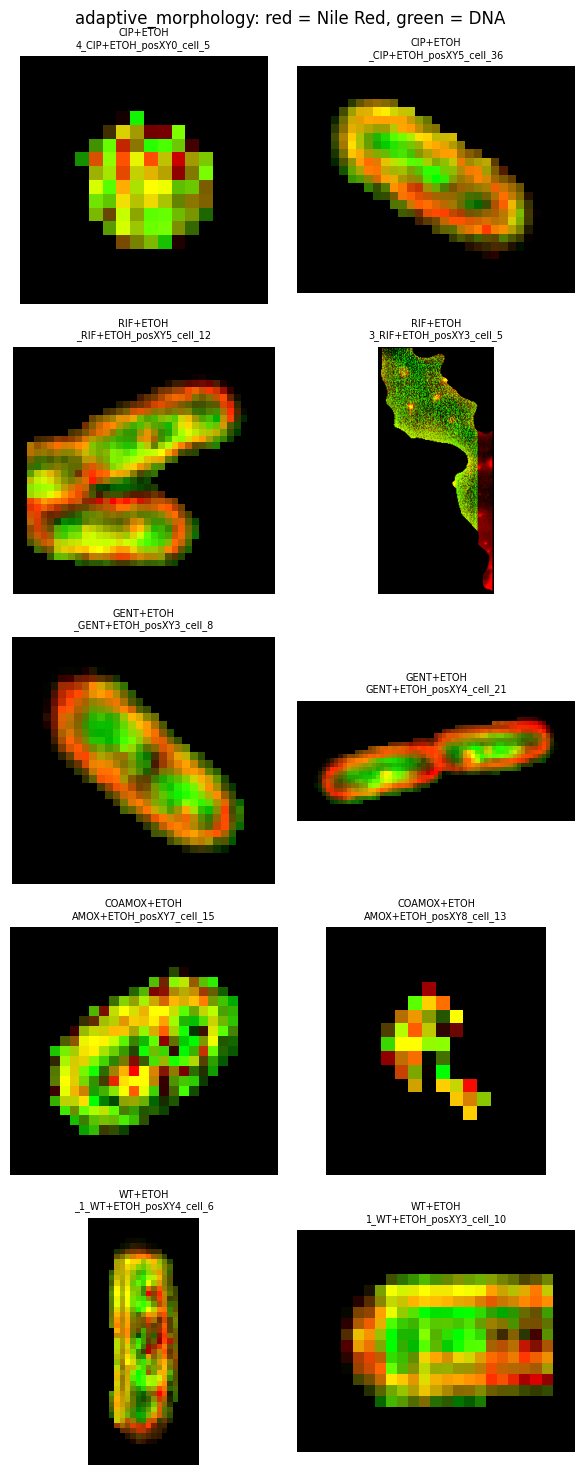

In [17]:
def _load_table(cm, kind):
    p = method_dir(cm) / "tables" / f"{cm}_{kind}.csv"
    return pd.read_csv(p) if p.exists() else None

cells_all = [d for d in (_load_table(cm, "cells") for cm in CELL_METHODS) if d is not None]
nuc_all   = [d for d in (_load_table(cm, "nucleoids") for cm in CELL_METHODS) if d is not None]
QC_OUT = DRIVE_ROOT / "metrics_all_methods"
QC_OUT.mkdir(parents=True, exist_ok=True)

if cells_all:
    cells_all = pd.concat(cells_all, ignore_index=True)
    pivot = cells_all.pivot_table(index="Treatment_Class", columns="Cell_Method",
                                  values="Cell_UID", aggfunc="count", fill_value=0)
    pivot.to_csv(QC_OUT / "cells_per_method_and_class.csv")
    pivot.plot(kind="bar", figsize=(9, 5), title="Segmented cells per treatment and method")
    plt.ylabel("Cells"); plt.tight_layout()
    plt.savefig(QC_OUT / "cells_per_method_and_class.png", dpi=200)
    plt.show()

    if nuc_all:
        nuc_all = pd.concat(nuc_all, ignore_index=True)
        nuc_pivot = nuc_all.pivot_table(index=["Cell_Method", "Nucleoid_Method"], columns="Treatment_Class",
                                        values="Nucleoid_UID", aggfunc="count", fill_value=0)
        nuc_pivot.to_csv(QC_OUT / "nucleoids_per_method_and_class.csv")
        display(nuc_pivot)
else:
    print("No cell tables on Drive yet. Run the pipeline first.")


def show_sample_grid(cm, n_per_class=2):
    """Sample individual cells from Drive (zip or folder, depending on CELLS_AS_ZIP)."""
    zpath, fpath = method_dir(cm) / "individual_cells.zip", method_dir(cm) / "individual_cells"
    if zpath.exists():
        z = zipfile.ZipFile(zpath)
        names = [n for n in z.namelist() if n.endswith(".png")]
        open_img = lambda n: plt.imread(z.open(n), format="png")
        in_class = lambda n, t: f"/{t}/" in "/" + n
        label_of = lambda n: Path(n).stem
    elif fpath.exists():
        names = [str(p) for p in fpath.rglob("*.png")]
        open_img = lambda n: plt.imread(n)
        in_class = lambda n, t: f"/{t}/" in n
        label_of = lambda n: Path(n).stem
    else:
        print(f"[{cm}] no individual cell images on Drive"); return

    fig, axes = plt.subplots(len(CLASSES), n_per_class, figsize=(3 * n_per_class, 3 * len(CLASSES)), squeeze=False)
    for i, t in enumerate(CLASSES):
        pool = [n for n in names if in_class(n, t)]
        picks = random.sample(pool, min(n_per_class, len(pool)))
        for j in range(n_per_class):
            ax = axes[i][j]; ax.axis("off")
            if j < len(picks):
                ax.imshow(open_img(picks[j])); ax.set_title(f"{t}\n{label_of(picks[j])[-24:]}", fontsize=7)
    fig.suptitle(f"{cm}: red = Nile Red, green = DNA", fontsize=12)
    plt.tight_layout(); plt.show()


for cm in CELL_METHODS:
    show_sample_grid(cm)

## Ground truth: unzip annotations and copy matching masks

In [18]:
GT_ZIP = Path("/content/drive/MyDrive/Research/All Segments.zip")
GT_RAW = Path("/content/gt_raw")

# 1) unzip (skipped if already extracted in this session)
if not GT_RAW.exists():
    GT_RAW.mkdir(parents=True)
    with zipfile.ZipFile(GT_ZIP) as z:
        z.extractall(GT_RAW)

# 2) index every mask by filename stem (works whatever the folder depth inside the zip)
gt_index = {p.stem: p for p in GT_RAW.rglob("*.tif*")}
print("Annotation files found:", len(gt_index))

# 3) copy the matching masks into /content/ground_truth/<class>/<image_name>.tif
found, missing = 0, []
for t in CLASSES:
    (GROUND_TRUTH_DIR / t).mkdir(parents=True, exist_ok=True)
    for img in (INPUT_DIR / t).glob("*.tif*"):
        if img.stem in gt_index:
            shutil.copy(gt_index[img.stem], GROUND_TRUTH_DIR / t / f"{img.stem}.tif")
            found += 1
        else:
            missing.append(img.stem)

print(f"Images with ground truth: {found} | without: {len(missing)}")
if missing:
    print("Example image name :", missing[0])
    print("Example mask name  :", next(iter(gt_index), None))

shutil.rmtree(GT_RAW)      # free disk space, the needed masks are already copied

Annotation files found: 1568
Images with ground truth: 1568 | without: 0


## Segmentation metrics (computed from the masks SAVED ON DRIVE)
Runs for **every cell method** that has saved masks on Drive and ground-truth masks in `GROUND_TRUTH_DIR/<class>/<image_name>.tif`.
* **Jaccard Index** at each IoU threshold = TP / (TP + FP + FN), with one-to-one Hungarian matching.
* The curve is **pooled** over all images (sum TP/FP/FN first, then ratio), so images with more cells count proportionally.
* `Segmentation_Error_Rate` = (FP + FN) / GT cells × 100 at IoU ≥ 0.50.

Saved to Drive: per method in `results/<method>/metrics/`, combined in `results/metrics_all_methods/`.

,Mean_Matched_IoU@0.5,Percent_GT_IoU>=0.80,Segmentation_Error_Rate,Images_Scored
Cell_Method,,,,
adaptive_morphology,0.809,40.906,73.873,1568
cellpose_omni,0.674,20.842,119.498,1568
marker_watershed,0.684,18.771,150.179,1568


Cell_Method,adaptive_morphology,cellpose_omni,marker_watershed
IoU_Threshold,,,
0.50,0.294,0.226,0.221
0.55,0.268,0.140,0.157
0.60,0.254,0.104,0.121
0.65,0.244,0.087,0.100
0.70,0.234,0.076,0.088
0.75,0.222,0.065,0.078
0.80,0.205,0.051,0.068
0.85,0.176,0.035,0.055
0.90,0.110,0.017,0.037


Cell_Method,adaptive_morphology,cellpose_omni,marker_watershed
Treatment_Class,,,
CIP+ETOH,75.6,133.5,146.0
COAMOX+ETOH,83.5,117.3,180.7
GENT+ETOH,62.7,120.1,136.7
RIF+ETOH,76.3,115.6,126.8
WT+ETOH,68.9,114.7,149.5


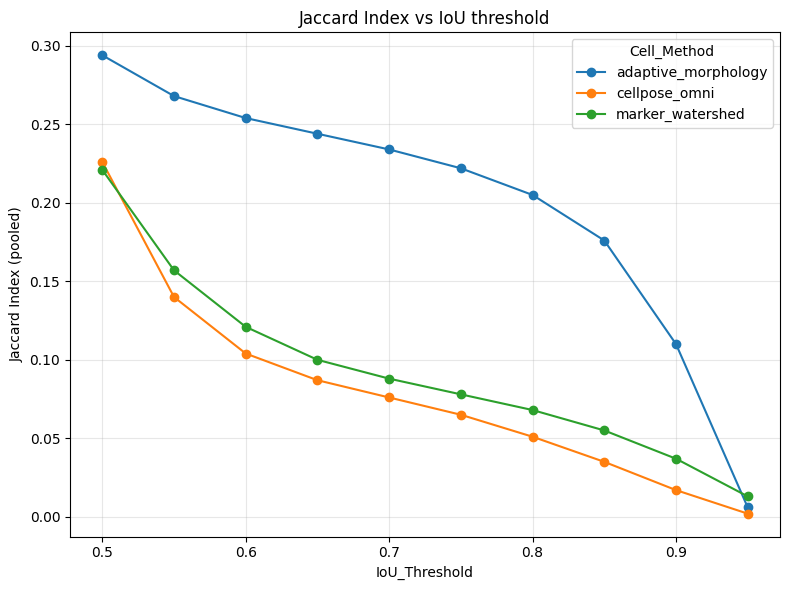

Area_um2  Length_um  Width_um  \
Cell_Method         Treatment_Class                                  
adaptive_morphology CIP+ETOH           31.795      4.417     2.072   
                    COAMOX+ETOH        54.936      5.588     2.714   
                    GENT+ETOH          28.477      4.343     2.014   
                    RIF+ETOH           23.886      4.121     1.889   
                    WT+ETOH            29.904      4.402     2.023   
cellpose_omni       CIP+ETOH            0.937      2.230     0.570   
                    COAMOX+ETOH         1.132      2.725     0.583   
                    GENT+ETOH           0.917      2.300     0.556   
                    RIF+ETOH            1.020      2.250     0.603   
                    WT+ETOH             1.032      2.424     0.578   
marker_watershed    CIP+ETOH            1.154      1.469     0.894   
                    COAMOX+ETOH         1.093      1.466     0.880   
                    GENT+ETOH           1.102      1.474     0.892   
                    RIF+ETOH            1.216      1.508     0.918   
                    WT+ETOH             1.109      1.445     0.866   

                                     Aspect_Ratio  
Cell_Method         Treatment_Class                
adaptive_morphology CIP+ETOH                2.751  
                    COAMOX+ETOH             2.858  
                    GENT+ETOH               2.747  
                    RIF+ETOH                2.754  
                    WT+ETOH                 2.843  
cellpose_omni       CIP+ETOH                4.324  
                    COAMOX+ETOH             5.345  
                    GENT+ETOH               4.514  
                    RIF+ETOH                4.123  
                    WT+ETOH                 4.583  
marker_watershed    CIP+ETOH                1.670  
                    COAMOX+ETOH             1.701  
                    GENT+ETOH               1.689  
                    RIF+ETOH                1.678  
                    WT+ETOH                 1.697

Metrics saved to /content/drive/MyDrive/Research/results/metrics_all_methods


In [19]:
def iou_matrix(gt, pred):
    """IoU between every GT and predicted instance (rows = GT, cols = pred) via one bincount."""
    gt, _, _ = relabel_sequential(np.asarray(gt).astype(np.int64))
    pred, _, _ = relabel_sequential(np.asarray(pred).astype(np.int64))
    n_gt, n_pred = int(gt.max()), int(pred.max())
    if n_gt == 0 or n_pred == 0:
        return np.zeros((n_gt, n_pred))
    overlap = np.bincount((gt.ravel() * (n_pred + 1) + pred.ravel()),
                          minlength=(n_gt + 1) * (n_pred + 1)).reshape(n_gt + 1, n_pred + 1).astype(np.float64)
    gt_area, pred_area = overlap[1:, :].sum(1), overlap[:, 1:].sum(0)
    inter = overlap[1:, 1:]
    return inter / (gt_area[:, None] + pred_area[None, :] - inter)


def evaluate_pair(pred, gt):
    iou = iou_matrix(gt, pred)
    n_gt, n_pred = iou.shape
    if n_gt and n_pred:
        r, c = linear_sum_assignment(-iou)
        matched = iou[r, c]
    else:
        matched = np.array([])

    rows = []
    for t in IOU_THRESHOLDS:
        tp = int((matched >= t).sum())
        rows.append({"IoU_Threshold": t, "TP": tp, "FP": n_pred - tp, "FN": n_gt - tp})

    tp50 = int((matched >= 0.5).sum())
    summary = {
        "GT_Cells": n_gt, "Pred_Cells": n_pred, "Matched_Cells@0.5": tp50,
        "Mean_Matched_IoU@0.5": float(matched[matched >= 0.5].mean()) if tp50 else 0.0,
        "Percent_GT_IoU>=0.80": 100.0 * (matched >= PRIMARY_IOU_THRESHOLD).sum() / n_gt if n_gt else np.nan,
        "Segmentation_Error_Rate": 100.0 * ((n_pred - tp50) + (n_gt - tp50)) / n_gt if n_gt else np.nan,
    }
    return summary, rows


def evaluate_method_from_drive(cm):
    """Score the masks stored on Drive for one cell method against ground truth; save metric CSVs to Drive."""
    mask_root = method_dir(cm) / "masks" / "cells"
    if not mask_root.exists():
        print(f"[{cm}] no saved masks on Drive -> run the pipeline first"); return None, None
    summ_rows, thr_rows = [], []
    for treatment in CLASSES:
        gt_dir = GROUND_TRUTH_DIR / treatment
        if not gt_dir.exists():
            continue
        for pred_path in sorted((mask_root / treatment).glob("*_cellmask.tif")):
            fname = pred_path.name.replace("_cellmask.tif", "")
            gt_path = gt_dir / f"{fname}.tif"
            if not gt_path.exists():
                continue                                   # image has no annotation
            pred, gt = tifffile.imread(str(pred_path)), tifffile.imread(str(gt_path))
            if pred.shape != gt.shape:
                print(f"Shape mismatch, skipped: {fname}"); continue
            summ, rows = evaluate_pair(pred, gt)
            meta = {"Cell_Method": cm, "Treatment_Class": treatment, "Image_ID": fname}
            summ_rows.append({**meta, **summ})
            thr_rows.extend({**meta, **r} for r in rows)
    if not summ_rows:
        print(f"[{cm}] no GT-matched images"); return None, None

    mdir = method_dir(cm) / "metrics"; mdir.mkdir(parents=True, exist_ok=True)
    per_image = pd.DataFrame(summ_rows)
    per_image.to_csv(mdir / "segmentation_evaluation_per_image.csv", index=False)

    th = pd.DataFrame(thr_rows).groupby(["Cell_Method", "IoU_Threshold"])[["TP", "FP", "FN"]].sum().reset_index()
    th["Jaccard_Index"] = th["TP"] / (th["TP"] + th["FP"] + th["FN"]).replace(0, np.nan)
    th.to_csv(mdir / "jaccard_vs_iou_threshold.csv", index=False)

    (per_image.groupby("Treatment_Class")[["Mean_Matched_IoU@0.5", "Percent_GT_IoU>=0.80", "Segmentation_Error_Rate"]]
              .mean().round(3).reset_index().assign(Cell_Method=cm)
              .to_csv(mdir / "metrics_by_class.csv", index=False))
    return per_image, th


all_pi, all_th = [], []
for cm in CELL_METHODS:
    pi, th = evaluate_method_from_drive(cm)
    if pi is not None:
        all_pi.append(pi); all_th.append(th)

if all_pi:
    pi_all, th_all = pd.concat(all_pi, ignore_index=True), pd.concat(all_th, ignore_index=True)
    out = DRIVE_ROOT / "metrics_all_methods"; out.mkdir(exist_ok=True)

    cols = ["Mean_Matched_IoU@0.5", "Percent_GT_IoU>=0.80", "Segmentation_Error_Rate"]
    headline = pi_all.groupby("Cell_Method")[cols].mean().round(3)
    headline["Images_Scored"] = pi_all.groupby("Cell_Method")["Image_ID"].nunique()
    headline.to_csv(out / "headline_metrics.csv")
    display(headline)
    if headline["Images_Scored"].nunique() > 1:
        print("WARNING: methods were scored on different numbers of images, so the comparison is not fair.")

    ji_table = th_all.pivot(index="IoU_Threshold", columns="Cell_Method", values="Jaccard_Index").round(3)
    ji_table.to_csv(out / "jaccard_vs_iou_table.csv")
    display(ji_table)

    err_by_class = pi_all.pivot_table(index="Treatment_Class", columns="Cell_Method",
                                      values="Segmentation_Error_Rate", aggfunc="mean").round(1)
    err_by_class.to_csv(out / "error_rate_by_class.csv")
    display(err_by_class)

    pi_all.to_csv(out / "per_image_all_methods.csv", index=False)

    ji_table.plot(marker="o", figsize=(8, 6), title="Jaccard Index vs IoU threshold")
    plt.ylabel("Jaccard Index (pooled)"); plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(out / "jaccard_vs_iou_threshold.png", dpi=200); plt.show()

    # morphology comparison, read from the CSVs saved on Drive
    cells_m = pd.concat([_load_table(cm, "cells") for cm in CELL_METHODS if _load_table(cm, "cells") is not None],
                        ignore_index=True)
    morph = cells_m.groupby(["Cell_Method", "Treatment_Class"])[["Area_um2", "Length_um", "Width_um", "Aspect_Ratio"]].mean().round(3)
    morph.to_csv(out / "morphology_by_method_and_class.csv")
    display(morph)
    print("Metrics saved to", out)
else:
    print("No metrics computed (check the ground-truth cell and that methods are saved on Drive).")


--- Headline Metrics ---


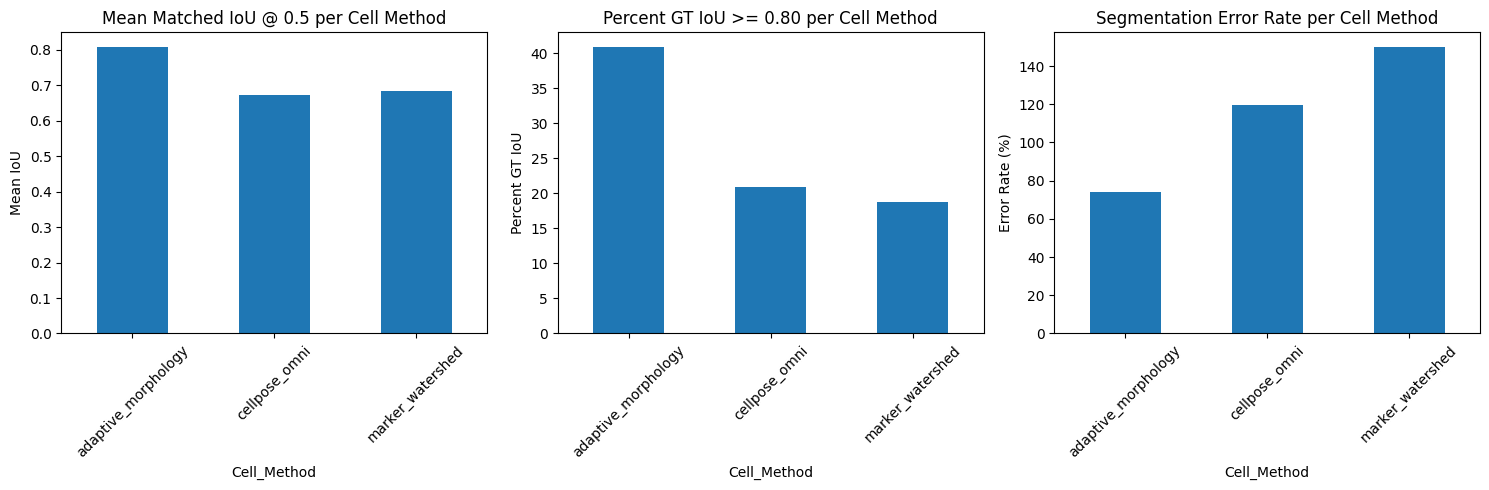

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. Plot headline metrics ---
print("\n--- Headline Metrics ---")
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
headline['Mean_Matched_IoU@0.5'].plot(kind='bar', ax=plt.gca(), rot=45)
plt.title('Mean Matched IoU @ 0.5 per Cell Method')
plt.ylabel('Mean IoU')
plt.tight_layout()

plt.subplot(1, 3, 2)
headline['Percent_GT_IoU>=0.80'].plot(kind='bar', ax=plt.gca(), rot=45)
plt.title('Percent GT IoU >= 0.80 per Cell Method')
plt.ylabel('Percent GT IoU')
plt.tight_layout()

plt.subplot(1, 3, 3)
headline['Segmentation_Error_Rate'].plot(kind='bar', ax=plt.gca(), rot=45)
plt.title('Segmentation Error Rate per Cell Method')
plt.ylabel('Error Rate (%)')
plt.tight_layout()

plt.show()


--- Jaccard Index vs IoU Threshold ---


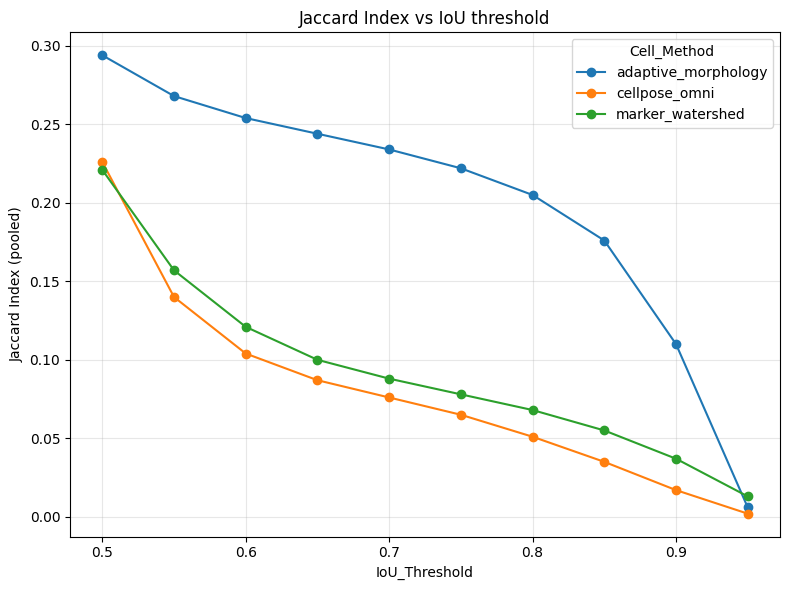

In [22]:
# --- 2. Plot Jaccard Index vs IoU threshold (reproducing the notebook's plot) ---
print("\n--- Jaccard Index vs IoU Threshold ---")
ji_table.plot(marker='o', figsize=(8, 6), title="Jaccard Index vs IoU threshold")
plt.ylabel("Jaccard Index (pooled)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


--- Segmentation Error Rate by Class and Method ---


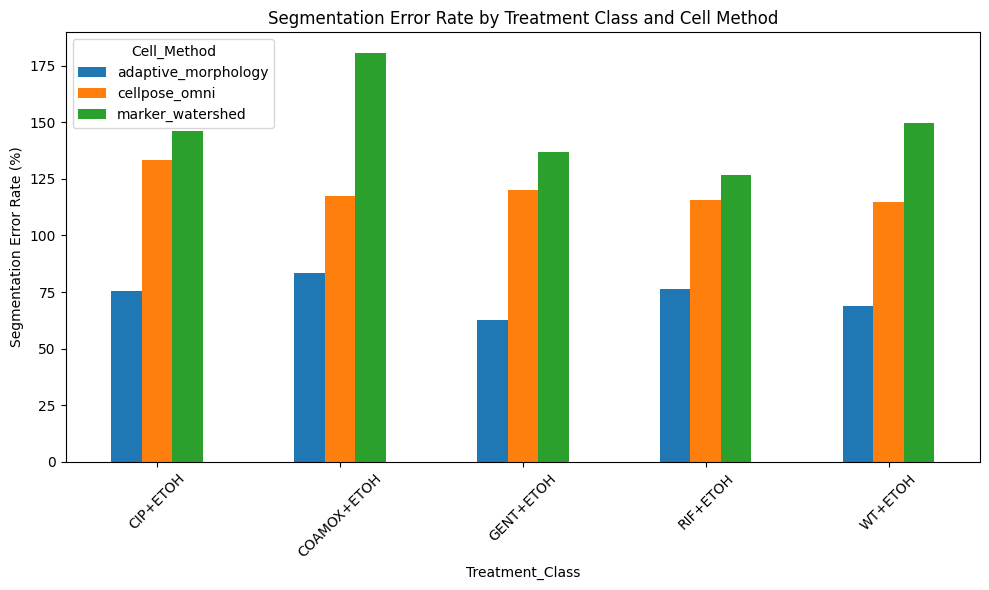

In [23]:
# --- 3. Plot Segmentation Error Rate by Treatment Class and Cell Method ---
print("\n--- Segmentation Error Rate by Class and Method ---")
err_by_class.plot(kind='bar', figsize=(10, 6), rot=45)
plt.title('Segmentation Error Rate by Treatment Class and Cell Method')
plt.ylabel('Segmentation Error Rate (%)')
plt.tight_layout()
plt.show()


--- Morphology Metrics ---


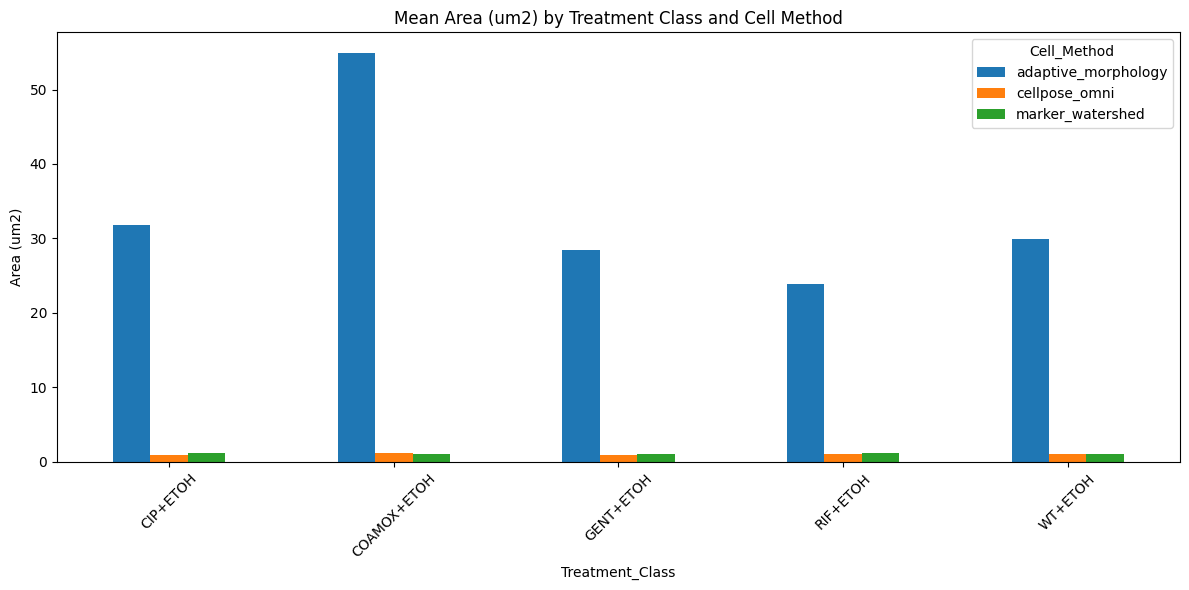

In [24]:
# --- 4. Plot Morphology Metrics by Treatment Class and Cell Method ---
print("\n--- Morphology Metrics ---")

morph_unstacked = morph.unstack(level='Cell_Method')

# Plot Area_um2
morph_unstacked['Area_um2'].plot(kind='bar', figsize=(12, 6), rot=45)
plt.title('Mean Area (um2) by Treatment Class and Cell Method')
plt.ylabel('Area (um2)')
plt.tight_layout()
plt.show()

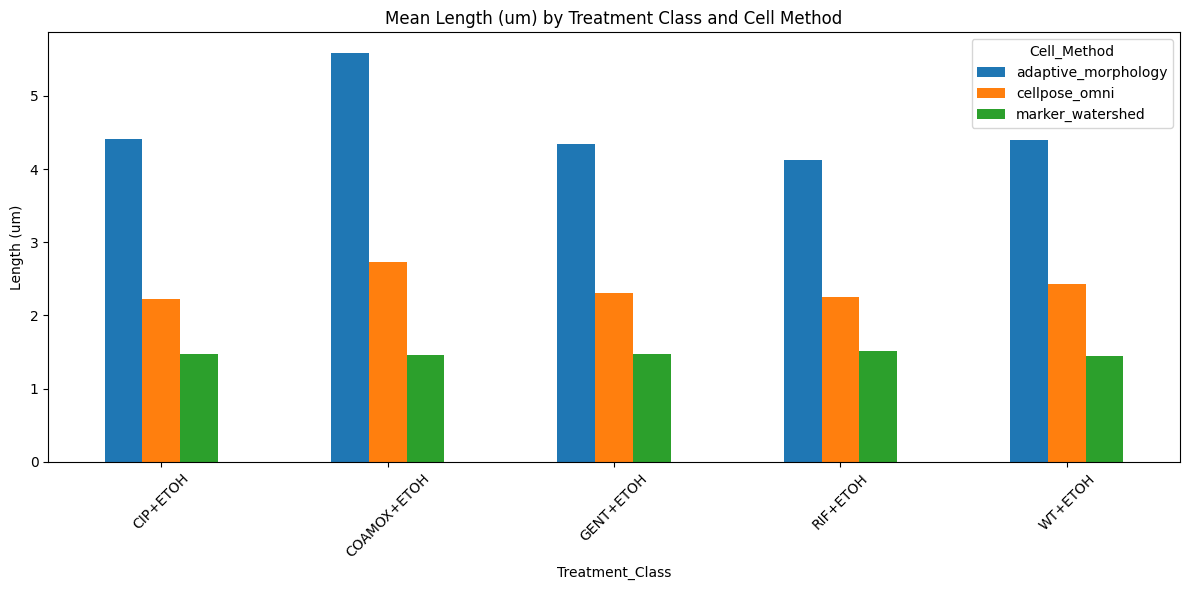

In [25]:
# Plot Length_um
morph_unstacked['Length_um'].plot(kind='bar', figsize=(12, 6), rot=45)
plt.title('Mean Length (um) by Treatment Class and Cell Method')
plt.ylabel('Length (um)')
plt.tight_layout()
plt.show()

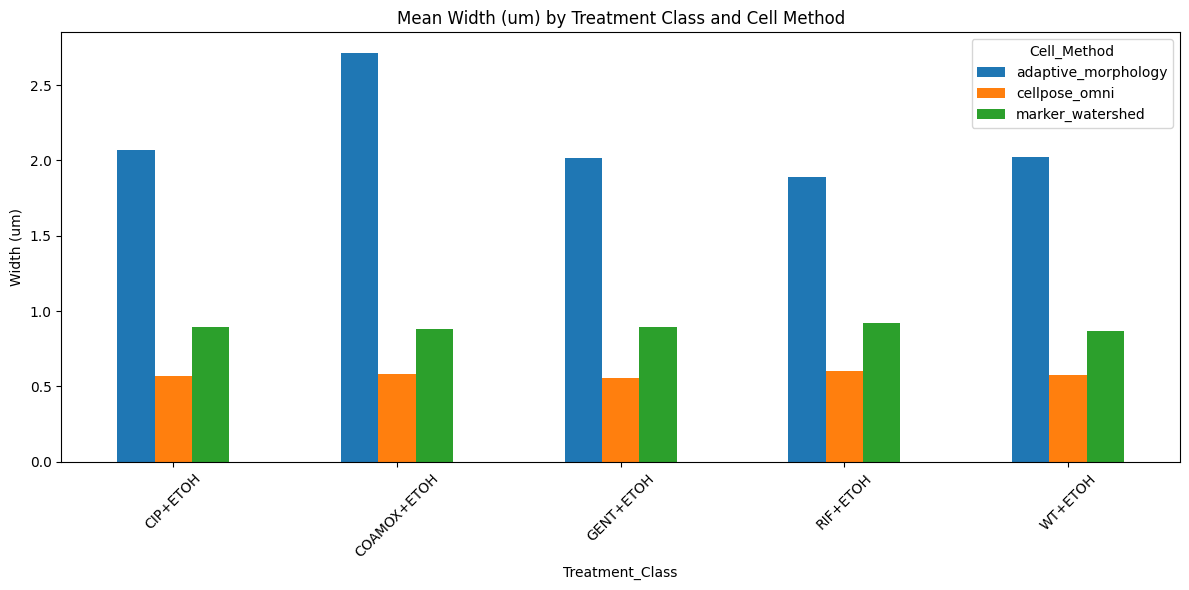

In [26]:
# Plot Width_um
morph_unstacked['Width_um'].plot(kind='bar', figsize=(12, 6), rot=45)
plt.title('Mean Width (um) by Treatment Class and Cell Method')
plt.ylabel('Width (um)')
plt.tight_layout()
plt.show()

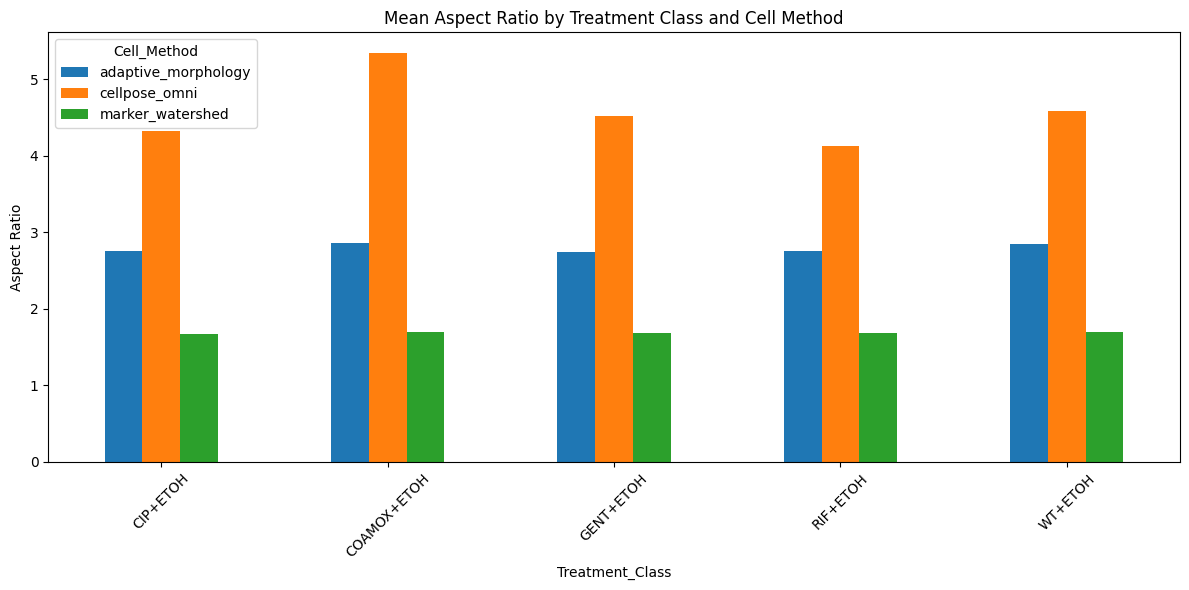

In [27]:
# Plot Aspect_Ratio
morph_unstacked['Aspect_Ratio'].plot(kind='bar', figsize=(12, 6), rot=45)
plt.title('Mean Aspect Ratio by Treatment Class and Cell Method')
plt.ylabel('Aspect Ratio')
plt.tight_layout()
plt.show()

## Download the metrics and tables to your computer

In [28]:
from google.colab import files

DL = Path("/content/csv_bundle")
shutil.rmtree(DL, ignore_errors=True)
for cm in CELL_METHODS:
    for sub in ["tables", "metrics", "qc"]:
        src = method_dir(cm) / sub
        if src.exists():
            shutil.copytree(src, DL / cm / sub, dirs_exist_ok=True)
if (DRIVE_ROOT / "metrics_all_methods").exists():
    shutil.copytree(DRIVE_ROOT / "metrics_all_methods", DL / "metrics_all_methods", dirs_exist_ok=True)

shutil.make_archive("/content/amr_csv_bundle", "zip", DL)
files.download("/content/amr_csv_bundle.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>